Erste Code-Version mithilfe von Claude Opus 5.5, Anpassungen erfolgten daraufhin eigenständig.

In [82]:
using LinearAlgebra
using Plots

const G = 2.95912208286e-4 # Gravitationskonstante in AU^3 / (M_sun * Tag^2)
const m_sun = 1.00000597682 # Masse der Sonne in M_sun (inklusive der inneren Planeten)
const GM = G * m_sun

0.00029591397690000476

## Teil 3: Das äußere Sonnensystem

Jetzt betrachten wir die Sonne, Jupiter, Saturn, Uranus, Neptun und Pluto (die inneren Planeten sind in der Masse der Sonne enthalten) – und die Sonne darf sich auch bewegen. Der Zustand ist jetzt eine $3 \times N$-Matrix $q$ (und $v$), wobei jede *Spalte* ein Körper ist. Die Anfangsdaten stammen aus dem Buch *Geometric Numerical Integration* von Hairer, Lubich und Wanner (Kap. I.2.4) und sind unten gegeben.

Die Beschleunigung von Körper $i$ ist
$$
a_i = \sum_{j \neq i} G\, m_j\, \frac{q_j - q_i}{\|q_j - q_i\|^3},
$$
die Gesamtenergie und der Gesamtdrehimpuls sind
$$
E = \sum_i \frac{1}{2} m_i \|v_i\|^2 - \sum_{i<j} \frac{G\, m_i m_j}{\|q_i - q_j\|}, \qquad L = \sum_i m_i\, q_i \times v_i .
$$

In [83]:
# Anfangsdaten. Return: Namen, Massen m (Länge N), Positionen q (3 x N), Geschwindigkeiten v (3 x N)
function outer_solar_system()
    names = ["Sun", "Jupiter", "Saturn", "Uranus", "Neptune", "Pluto"]
    m = [1.00000597682, 0.000954786104043, 0.000285583733151,
         0.0000437273164546, 0.0000517759138449, 1 / 1.3e8]
    q = [0.0 -3.5023653 9.0755314 8.3101420 11.4707666 -15.5387357 ;
         0.0 -3.8169847 -3.0458353 -16.2901086 -25.7294829 -25.2225594 ;
         0.0 -1.5507963 -1.6483708 -7.2521278 -10.8169456 -3.1902382]
    v = [0.0 0.00565429 0.00168318 0.00354178 0.00288930 0.00276725 ;
         0.0 -0.00412490 0.00483525 0.00137102 0.00114527 -0.00170702 ;
         0.0 -0.00190589 0.00192462 0.00055029 0.00039677 -0.00136504]
    return names, m, q, v
end

outer_solar_system (generic function with 1 method)

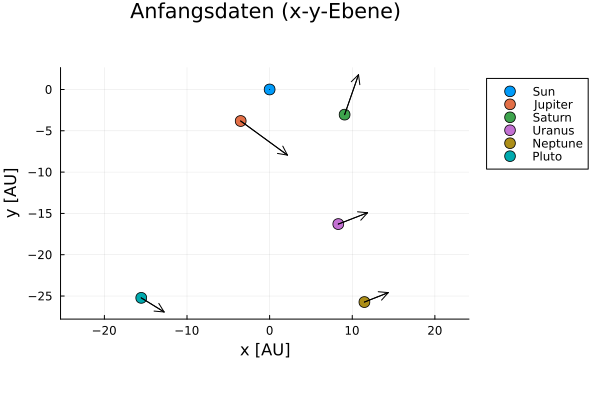

In [84]:
names, m, q, v = outer_solar_system()

p = plot(; aspect_ratio = :equal, xlabel = "x [AU]", ylabel = "y [AU]", title = "Anfangsdaten (x-y-Ebene)", legend = :outertopright)

for i in eachindex(names)
    scatter!(p, [q[1, i]], [q[2, i]]; label = names[i], markersize = 6)
end

# Geschwindigkeiten als Pfeile (skaliert, sonst unsichtbar klein)
s = 1000   # Pfeil = Strecke, die in 1000 Tagen mit v = konst. zurückgelegt werden würde
quiver!(p, q[1, :], q[2, :]; quiver = (s * v[1, :], s * v[2, :]), color = :black)

p

In den gegebenen Daten ruht die Sonne, der Schwerpunkt des Systems bewegt sich aber. Schreibe eine Funktion
```julia
raw"""
shifts positions q and velocities v (3 x N matrices) in place, such that the center of mass Q = sum_i m_i q_i / sum_i m_i is at the origin and the total momentum sum_i m_i v_i is zero
"""
function to_barycentre!(q, v, m)
    ...
end
```
Die Funktion soll die Positionen und Geschwindigkeiten **in-place** transformieren:
$$
q_i \to q_i - Q \\
v_i \to v_i - V
$$
wobei $Q =  \frac{1}{M} \sum_{i} m_i q_i ,  V = \frac{1}{M} \sum_i m_i v_i$ und $M = \sum_i m_i$

Transformiere die Anfangsdaten in dieses Koordinatensystem.


In [85]:
function to_barycentre!(q, v, m)
    M = sum(m)
    Q = q * m/M
    V = v * m/M
    q .-= Q
    v .-= V
    return q, v
end

names, m, q0, v0 = outer_solar_system()
to_barycentre!(q0, v0, m);

Implementiere die Funktionen
```julia
acceleration_nbody(q, m)           # returns a 3 x N matrix with the accelerations a_i
energy_nbody(q, v, m)              # total energy E
angular_momentum_nbody(q, v, m)    # total angular momentum L (3-vector)
```
Testet `acceleration_nbody`: Nach dem dritten Newtonschen Gesetz muss $\sum_i m_i a_i = 0$ gelten.

In [86]:
function acceleration_nbody(q, m)
    N = length(m)
    a = zeros(3, N)
    for i in 1:N, j in 1:N
        i == j && continue # Selbstwechselwirkung überspringen
        d = q[:, j] - q[:, i]
        a[:, i] += G * m[j] * d / norm(d)^3
    end
    return a
end

function energy_nbody(q, v, m)
    N = length(m)
    E = 0.0
    for i in 1:N
        E += 0.5 * m[i] * dot(v[:, i], v[:, i])
        for j in i+1:N
            E -= G * m[i] * m[j] / norm(q[:, i] - q[:, j])
        end
    end
    return E
end

function angular_momentum_nbody(q, v, m)
    L = zeros(3)
    for i in eachindex(m)
        L += m[i] * cross(q[:, i], v[:, i])
    end
    return L
end

norm(acceleration_nbody(q0, m) * m) # soll annähernd null sein, wegen 3. Newton Gesetz

1.3974511994897761e-24

### Zeitintegratoren (aus Teil 1)

In [87]:
function euler_step(acc, q, v, h)
    q_new = q + h * v
    v_new = v + h * acc(q)
    return q_new, v_new
end

function integrate(step, acc, q_0, v_0, h, N_steps)
    t  = [n * h for n in 0:N_steps]
    qs = [copy(q_0)]
    vs = [copy(v_0)]
    q, v = copy(q_0), copy(v_0)
    for n in 1:N_steps
        q, v = step(acc, q, v, h)
        push!(qs, q)
        push!(vs, v)
    end
    return t, qs, vs
end

function verlet_step(acc, q, v, h)
    v_half = v + (h / 2) * acc(q)
    q_new  = q + h * v_half
    v_new  = v_half + (h / 2) * acc(q_new)
    return q_new, v_new
end

verlet_step (generic function with 1 method)

Simuliere das äußere Sonnensystem für $2000$ Zeitschritte mit `h = 100` Tagen (also ca. 548 Jahre) mit dem **expliziten Eulerverfahren** und mit **Störmer–Verlet**. Plotte
* die Bahnen aller Körper in der $x$-$y$-Ebene,
* den relativen Energiefehler und
* den relativen Fehler vom Gesamtdrehimpuls

als Funktion der Zeit für beide Verfahren

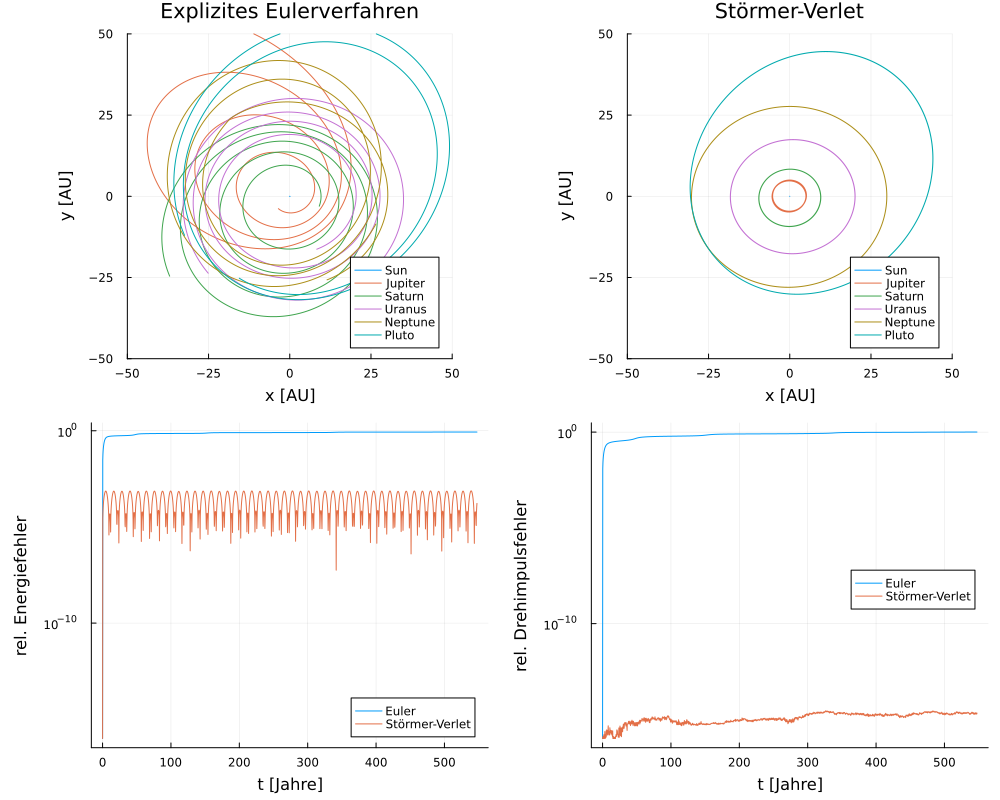

In [88]:
acc = q -> acceleration_nbody(q, m)
h = 100.0
N_steps = 2000

t_e, q_e, v_e = integrate(euler_step,  acc, q0, v0, h, N_steps)
t_v, q_v, v_v = integrate(verlet_step, acc, q0, v0, h, N_steps)

clip(x) = max(x, 1e-16)

function relative_errors(qs, vs, m)
    E = [energy_nbody(q, v, m) for (q, v) in zip(qs, vs)]
    L = [angular_momentum_nbody(q, v, m) for (q, v) in zip(qs, vs)]
    errE = abs.(E .- E[1]) ./ abs(E[1])
    errL = [norm(l - L[1]) / norm(L[1]) for l in L]
    return errE, errL
end

errE_e, errL_e = relative_errors(q_e, v_e, m)
errE_v, errL_v = relative_errors(q_v, v_v, m)

function plot_orbits(qs, names; title = "")
    p = plot(; xlims = (-50, 50), ylims = (-50, 50), aspect_ratio = :equal, xlabel = "x [AU]", ylabel = "y [AU]", title = title, legend = :bottomright)
    for i in eachindex(names)
        plot!(p, [q[1, i] for q in qs], [q[2, i] for q in qs]; label = names[i])
    end
    return p
end

p1 = plot_orbits(q_e, names; title = "Explizites Eulerverfahren")
p2 = plot_orbits(q_v, names; title = "Störmer-Verlet")

p3 = plot(t_e ./ 365.25, clip.(errE_e), yscale = :log10, label = "Euler", xlabel = "t [Jahre]", ylabel = "rel. Energiefehler", legend = :bottomright)
plot!(p3, t_v ./ 365.25, clip.(errE_v), label = "Störmer-Verlet")

p4 = plot(t_e ./ 365.25, clip.(errL_e), yscale = :log10, label = "Euler", xlabel = "t [Jahre]", ylabel = "rel. Drehimpulsfehler", legend = :right)
plot!(p4, t_v ./ 365.25, clip.(errL_v), label = "Störmer-Verlet")

plot(p1, p2, p3, p4, layout = (2, 2), size = (1000, 800), left_margin = 5Plots.mm)

**Ergebnis**
* **Euler:** Energie & Drehimpuls driften nahezu sofort ab (rel. Fehler $\approx 1$), die Planeten verlassen die festen Bahnen als Spiralen.
* **Störmer–Verlet:** Bahnen bleiben über $500+$ Jahre stabil. Der Energiefehler bleibt beschränkt und schwingt mit der Jupiterperiode ($\approx 12$ Jahre). Der Drehimpuls ist bis auf Rundungsfehler ($\approx 10^{-15}$) erhalten.
* **Grund:** Strömer-Verlet ist symplektisch (Phasenraumvolumen der Simulation, gleich dem der Planetendynamik), Euler nicht. Bei gleichem Aufwand pro Schritt ist Verlet für Langzeitsimulationen klar besser.

### Animation: Euler vs. Störmer–Verlet

┌ Info: Saved animation to c:\Users\mikar\Documents\math-programs\sonnensystem.gif
└ @ Plots C:\Users\mikar\.julia\packages\Plots\8ZnR3\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\mikar\\Documents\\math-programs\\sonnensystem.gif")
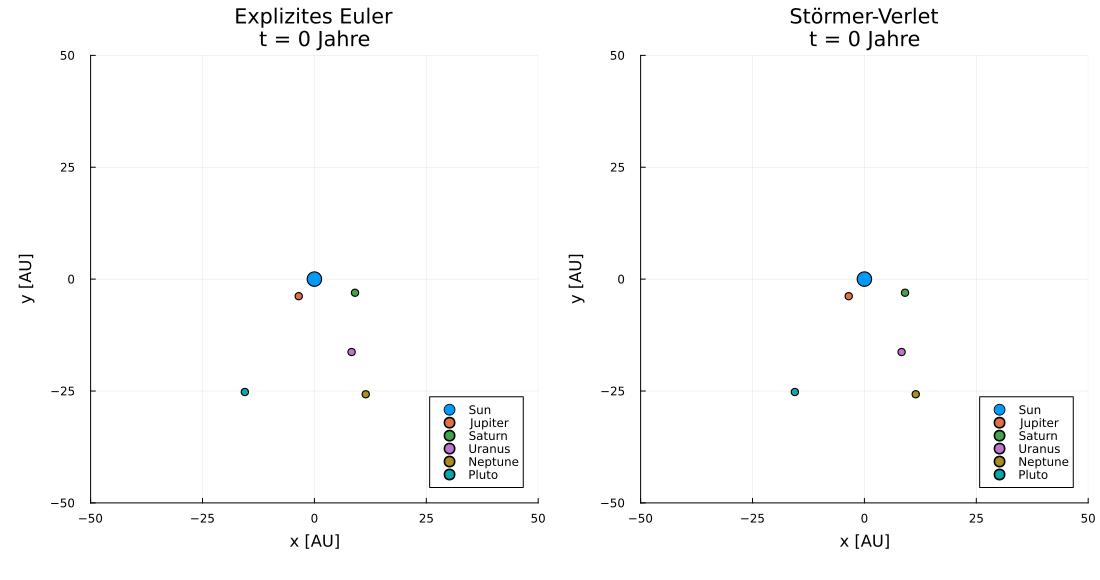

In [89]:
gr() # Backend

# ein Bild der Animation: aktuelle Positionen + bisherige Spur
function frame_plot(qs, t, n, names; title = "")
    p = plot(; xlims = (-50, 50), ylims = (-50, 50), aspect_ratio = :equal, xlabel = "x [AU]", ylabel = "y [AU]", legend = :bottomright, title = "$title\nt = $(round(Int, t[n] / 365.25)) Jahre")
    for i in eachindex(names)
        plot!(p, [q[1, i] for q in qs[1:n]], [q[2, i] for q in qs[1:n]]; color = i, label = "") # Spur
        scatter!(p, [qs[n][1, i]], [qs[n][2, i]]; color = i, markersize = i == 1 ? 8 : 4, label = names[i]) # Körper
    end
    return p
end

step_every = 10 # sonst 2001 Bilder

anim = @animate for n in 1:step_every:length(q_v)
    pe = frame_plot(q_e, t_e, n, names; title = "Explizites Euler")
    pv = frame_plot(q_v, t_v, n, names; title = "Störmer-Verlet")
    plot(pe, pv, layout = (1, 2), size = (1100, 580), left_margin = 8Plots.mm, bottom_margin = 8Plots.mm, top_margin = 3Plots.mm)
end

gif(anim, "sonnensystem.gif", fps = 20)